In [140]:
import pandas as pd
from sklearn.model_selection import train_test_split

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint


In [141]:
df = pd.read_csv("./process_files/pose.csv")

In [142]:
# dropping invalid rows
df = df[df["Label"] != -1]

In [143]:
from collections import Counter

X = df.iloc[:, 1:].values  # All landmark coordinates
y = df.iloc[:, 0].values   # Labels (1 = Awake, 0 = Sleeping)

dict_keys = Counter(y)

print(dict_keys)

Counter({1: 869, 0: 425})


In [144]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
# X = scaler.fit_transform(X)

# Split into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train = scaler.fit_transform(X_train)
X_test = scaler.fit_transform(X_test)

print(f"Training samples: {len(X_train)}, Testing samples: {len(X_test)}")

Training samples: 1035, Testing samples: 259


In [145]:
### TRAINING

## FOR HYPER TUNING THE PARAMS
param_dist = {'n_estimators': randint(50,500),
              'max_depth': randint(1,20),
              'random_state': randint(1,100),
              'class_weight': ['balanced', 'balanced_subsample']
              }

rf = RandomForestClassifier()

rand_search = RandomizedSearchCV(rf, 
                                 param_distributions = param_dist, 
                                 n_iter=8, 
                                 cv=5)

rand_search.fit(X_train, y_train)

best_rf = rand_search.best_estimator_

# Print the best hyperparameters
print('Best hyperparameters:',  rand_search.best_params_)

In [147]:

from imblearn.over_sampling import SMOTE
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import classification_report, f1_score
import xgboost as xgb
from xgboost import XGBClassifier

model = XGBClassifier(n_estimators=426, random_state=51, max_depth=4, scale_pos_weight=1)  # scale_pos_weight for imbalanced classes


model.fit(X_train, y_train)


# Predict on test set
y_pred = model.predict(X_test)



In [148]:
# TESTING
print(classification_report(y_test, y_pred))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=61)
scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='accuracy')

print(f"Cross-validation accuracy: {scores.mean():.2f}")

train_accuracy = model.score(X_train, y_train)
print(f"Training Accuracy: {train_accuracy:.4f}")
f1 = f1_score(y_test, y_pred)

print(f"F1 Score: {f1:.2f}")
# Evaluate performance
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.4f}")

              precision    recall  f1-score   support

           0       0.93      0.96      0.95        81
           1       0.98      0.97      0.97       178

    accuracy                           0.97       259
   macro avg       0.96      0.96      0.96       259
weighted avg       0.97      0.97      0.97       259

Cross-validation accuracy: 0.95
Training Accuracy: 1.0000
F1 Score: 0.97
Model Accuracy: 0.9653


In [149]:
# Testing on external data
df_ext = pd.read_csv("./process_files/test.csv")
df_ext = df_ext[df_ext["Label"] != -1]

X_ext = df_ext.iloc[:, 1:].values  # All landmark coordinates
y_ext = df_ext.iloc[:, 0].values   # Labels (1 = Awake, 0 = Sleeping)

dict_keys = Counter(y_ext)

print(dict_keys)

X_ext = scaler.transform(X_ext)

y_pred_ext = model.predict(X_ext)

print(classification_report(y_ext, y_pred_ext))

accuracy = accuracy_score(y_ext, y_pred_ext)
print(f"Model Accuracy: {accuracy:.4f}")

Counter({1: 50, 0: 50})
              precision    recall  f1-score   support

           0       0.96      1.00      0.98        50
           1       1.00      0.96      0.98        50

    accuracy                           0.98       100
   macro avg       0.98      0.98      0.98       100
weighted avg       0.98      0.98      0.98       100

Model Accuracy: 0.9800


In [151]:
import joblib

model_filename = 'server_code_sleep/pose_sleep_model.sav'
scaler_filename = 'server_code_sleep/pose_sleep_scaler.sav'

# Save the model and scaler
joblib.dump(model, model_filename)
joblib.dump(scaler, scaler_filename)

['server_code_sleep/pose_sleep_scaler.sav']

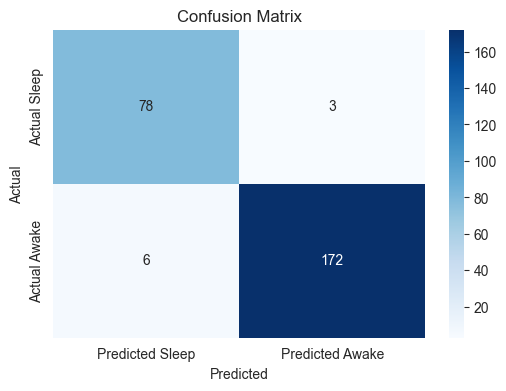

In [150]:
# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Predicted Sleep', 'Predicted Awake'], yticklabels=['Actual Sleep', 'Actual Awake'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()